Setup and Build

In [1]:
!apt-get update -qq
!apt-get install -y -qq g++ cmake ninja-build git python3-dev

!git clone --depth 1 --branch ns-3.43 \
https://gitlab.com/nsnam/ns-3-dev.git ns-3

%cd /content/ns-3

!./ns3 configure --enable-examples
!./ns3 build

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package javascript-common.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../0-javascript-common_11+nmu1_all.deb ...
Unpacking javascript-common (11+nmu1) ...
Selecting previously unselected package libjs-underscore.
Preparing to unpack .../1-libjs-underscore_1.13.4~dfsg+~1.11.4-3_all.deb ...
Unpacking libjs-underscore (1.13.4~dfsg+~1.11.4-3) ...
Selecting previously unselected package libjs-sphinxdoc.
Preparing to unpack .../2-libjs-sphinxdoc_7.2.6-6_all.deb ...
Unpacking libjs-sphinxdoc (7.2.6-6) ...
Selecting previously unselected package ninja-build.
Preparing to unpack .../3-ninja-build_1.11.1-2_amd64.deb ...
Unpacking ninja-build (1.11.1-2) ...
Selecting previously unselected package python3.12-dev.
Preparing to unpa

Experiment 3

In [27]:

%%writefile /content/ns-3/scratch/udp-echo-practical3.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/point-to-point-module.h"
#include "ns3/applications-module.h"

using namespace ns3;

int main()
{
    // Create two nodes
    NodeContainer nodes;
    nodes.Create(2);

    // Configure point-to-point link
    PointToPointHelper p2p;

    p2p.SetDeviceAttribute(
        "DataRate", StringValue("2Mbps"));

    p2p.SetChannelAttribute(
        "Delay", StringValue("2ms"));

    NetDeviceContainer devices = p2p.Install(nodes);

    // Install Internet stack
    InternetStackHelper stack;
    stack.Install(nodes);

    // Assign IP addresses
    Ipv4AddressHelper address;

    address.SetBase("10.1.1.0", "255.255.255.0");

    Ipv4InterfaceContainer interfaces =
        address.Assign(devices);

    uint16_t port = 9;

    // UDP Echo Server on Node 1
    UdpEchoServerHelper server(port);

    ApplicationContainer serverApp =
        server.Install(nodes.Get(1));

    serverApp.Start(Seconds(1.0));
    serverApp.Stop(Seconds(10.0));

    // UDP Echo Client on Node 0
    UdpEchoClientHelper client(
        interfaces.GetAddress(1), port);

    client.SetAttribute(
        "MaxPackets", UintegerValue(5));

    client.SetAttribute(
        "Interval", TimeValue(Seconds(1.0)));

    client.SetAttribute(
        "PacketSize", UintegerValue(1024));

    ApplicationContainer clientApp =
        client.Install(nodes.Get(0));

    clientApp.Start(Seconds(2.0));
    clientApp.Stop(Seconds(10.0));

    // Run simulation
    Simulator::Stop(Seconds(10.0));
    Simulator::Run();

    std::cout << "\n===== UDP ECHO RESULTS =====\n";
    std::cout << "Node 0 IP: "
              << interfaces.GetAddress(0) << "\n";

    std::cout << "Node 1 IP: "
              << interfaces.GetAddress(1) << "\n";

    std::cout << "Data Rate: 2 Mbps\n";
    std::cout << "Channel Delay: 2 ms\n";
    std::cout << "Maximum Packets: 5\n";
    std::cout << "Packet Size: 1024 bytes\n";
    std::cout << "============================\n";

    Simulator::Destroy();

    return 0;
}


Writing /content/ns-3/scratch/udp-echo-practical3.cc


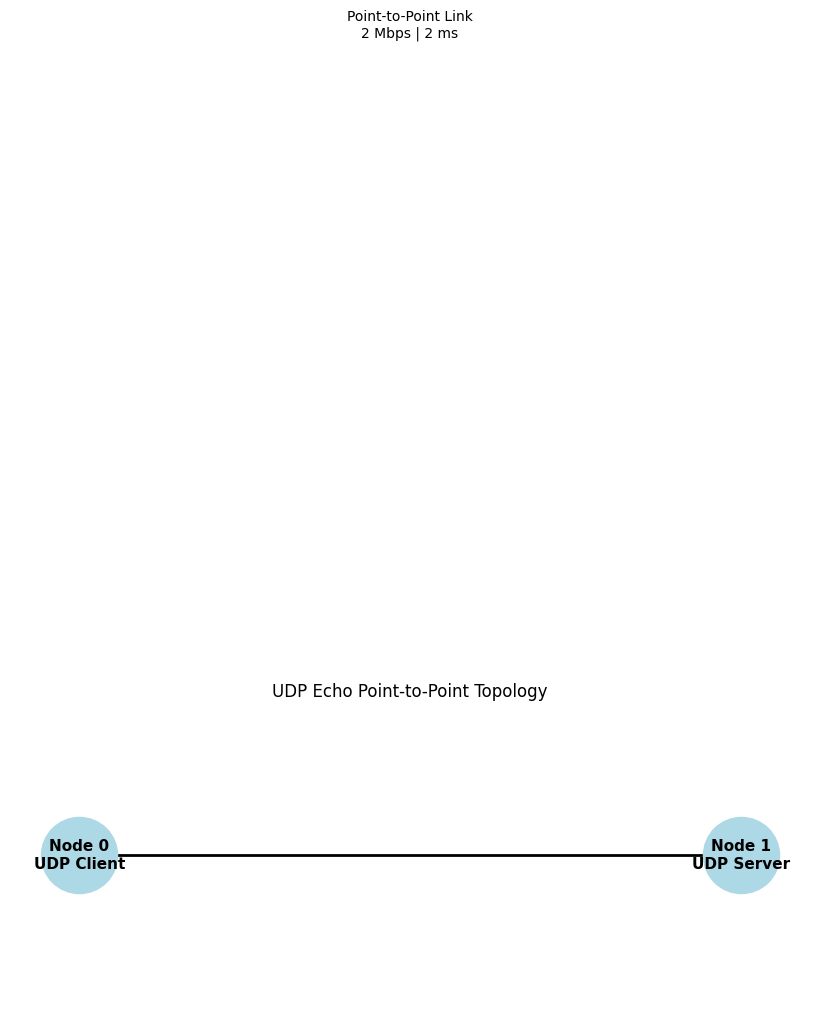

In [28]:

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_edge("Node 0\nUDP Client", "Node 1\nUDP Server")

pos = {
    "Node 0\nUDP Client": (0, 0),
    "Node 1\nUDP Server": (3, 0)
}

plt.figure(figsize=(8, 3))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=11,
    font_weight="bold",
    width=2
)

plt.text(
    1.5, 0.3,
    "Point-to-Point Link\n2 Mbps | 2 ms",
    ha="center"
)

plt.title("UDP Echo Point-to-Point Topology")
plt.axis("off")
plt.show()


In [29]:
%cd /content/ns-3
!./ns3 run scratch/udp-echo-practical3

/content/ns-3
-- Using default output directory /content/ns-3/build
-- Proceeding without cmake-format
-- find_external_library: SQLite3 was found.
CMake Warning (dev) at build-support/macros-and-definitions.cmake:839 (find_package):
  Policy CMP0167 is not set: The FindBoost module is removed.  Run "cmake
  --help-policy CMP0167" for policy details.  Use the cmake_policy command to
  set the policy and suppress this warning.

Call Stack (most recent call first):
  CMakeLists.txt:154 (process_options)
This warning is for project developers.  Use -Wno-dev to suppress it.

-- docs: doxygen documentation not enabled due to missing dependencies: doxygen dia
-- docs: sphinx documentation not enabled due to missing dependencies: epstopdf pdflatex latexmk convert dvipng dia
-- Processing src/antenna
-- Standard library Bessel function has been found
-- Processing src/aodv
-- Processing src/applications
-- Processing src/bridge
-- Processing src/brite
-- Skipping src/brite
-- Processing src/bu

Experiment 4

In [23]:

%%writefile /content/ns-3/scratch/csma-p2p-practical4.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/point-to-point-module.h"
#include "ns3/csma-module.h"
#include "ns3/applications-module.h"

using namespace ns3;

int main()
{
    // Create two P2P nodes
    NodeContainer p2pNodes;
    p2pNodes.Create(2);

    PointToPointHelper p2p;
    p2p.SetDeviceAttribute("DataRate", StringValue("5Mbps"));
    p2p.SetChannelAttribute("Delay", StringValue("2ms"));

    NetDeviceContainer p2pDevices = p2p.Install(p2pNodes);

    // Create CSMA network with 4 nodes
    NodeContainer csmaNodes;
    csmaNodes.Add(p2pNodes.Get(1));
    csmaNodes.Create(3);

    CsmaHelper csma;
    csma.SetChannelAttribute("DataRate", StringValue("100Mbps"));
    csma.SetChannelAttribute("Delay", TimeValue(NanoSeconds(6560)));

    NetDeviceContainer csmaDevices = csma.Install(csmaNodes);

    // Install Internet stack on all unique nodes
    NodeContainer allNodes;
    allNodes.Add(p2pNodes.Get(0));
    allNodes.Add(p2pNodes.Get(1));
    allNodes.Add(csmaNodes.Get(1));
    allNodes.Add(csmaNodes.Get(2));
    allNodes.Add(csmaNodes.Get(3));

    InternetStackHelper stack;
    stack.Install(allNodes);

    // Assign P2P IP addresses
    Ipv4AddressHelper address;

    address.SetBase("10.1.1.0", "255.255.255.0");
    address.Assign(p2pDevices);

    // Assign CSMA IP addresses
    address.SetBase("10.1.2.0", "255.255.255.0");

    Ipv4InterfaceContainer csmaInterfaces =
        address.Assign(csmaDevices);

    // Enable routing
    Ipv4GlobalRoutingHelper::PopulateRoutingTables();

    // UDP Echo Server on Node 4
    UdpEchoServerHelper server(9);

    ApplicationContainer serverApp =
        server.Install(csmaNodes.Get(3));

    serverApp.Start(Seconds(1.0));
    serverApp.Stop(Seconds(10.0));

    // UDP Echo Client on Node 0
    UdpEchoClientHelper client(
        csmaInterfaces.GetAddress(3), 9);

    client.SetAttribute("MaxPackets", UintegerValue(5));
    client.SetAttribute("Interval", TimeValue(Seconds(1.0)));
    client.SetAttribute("PacketSize", UintegerValue(1024));

    ApplicationContainer clientApp =
        client.Install(p2pNodes.Get(0));

    clientApp.Start(Seconds(2.0));
    clientApp.Stop(Seconds(10.0));

    // Generate PCAP files
    p2p.EnablePcapAll("second");
    csma.EnablePcap("second", csmaDevices.Get(0), true);

    // Run simulation
    Simulator::Stop(Seconds(10.0));
    Simulator::Run();

    std::cout << "\n===== P2P AND CSMA RESULTS =====\n";
    std::cout << "P2P Bandwidth: 5 Mbps\n";
    std::cout << "CSMA Bandwidth: 100 Mbps\n";
    std::cout << "P2P Network: 10.1.1.0\n";
    std::cout << "CSMA Network: 10.1.2.0\n";
    std::cout << "UDP Packets: 5\n";
    std::cout << "Packet Size: 1024 bytes\n";
    std::cout << "================================\n";

    Simulator::Destroy();

    return 0;
}


Overwriting /content/ns-3/scratch/csma-p2p-practical4.cc


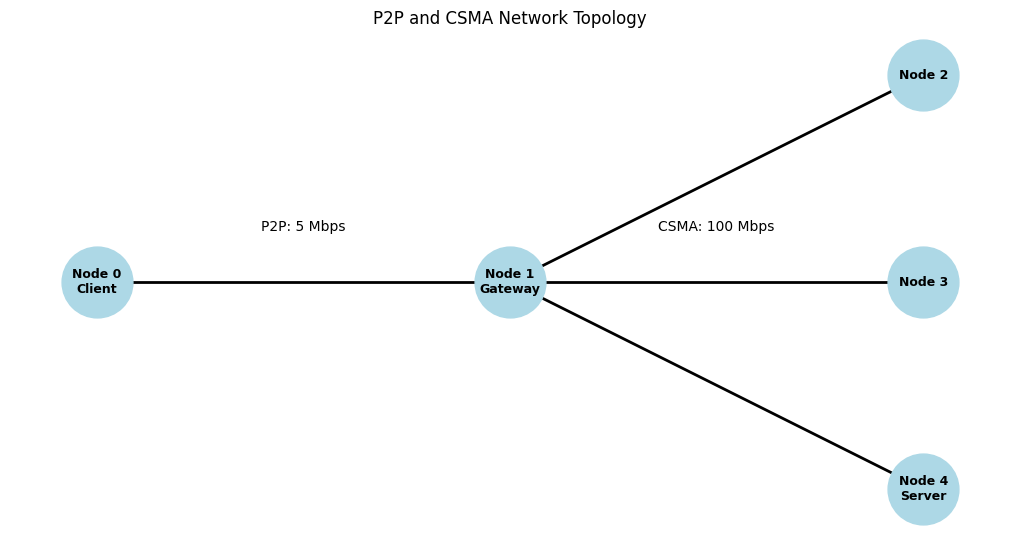

In [24]:

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_edges_from([
    ("Node 0\nClient", "Node 1\nGateway"),
    ("Node 1\nGateway", "Node 2"),
    ("Node 1\nGateway", "Node 3"),
    ("Node 1\nGateway", "Node 4\nServer")
])

pos = {
    "Node 0\nClient": (0, 0),
    "Node 1\nGateway": (2, 0),
    "Node 2": (4, 1),
    "Node 3": (4, 0),
    "Node 4\nServer": (4, -1)
}

plt.figure(figsize=(10, 5))

nx.draw(G, pos, with_labels=True,
        node_size=2600, node_color="lightblue",
        font_size=9, font_weight="bold",
        width=2)

plt.text(1, 0.25, "P2P: 5 Mbps", ha="center")
plt.text(3, 0.25, "CSMA: 100 Mbps", ha="center")

plt.title("P2P and CSMA Network Topology")
plt.axis("off")
plt.show()


In [25]:
%cd /content/ns-3
!./ns3 run scratch/csma-p2p-practical4

/content/ns-3
[0/2] Re-checking globbed directories...
[2/2] Linking CXX executable /content/ns-3/build/scratch/ns3.43-csma-p2p-practical4-default

===== P2P AND CSMA RESULTS =====
P2P Bandwidth: 5 Mbps
CSMA Bandwidth: 100 Mbps
P2P Network: 10.1.1.0
CSMA Network: 10.1.2.0
UDP Packets: 5
Packet Size: 1024 bytes


In [26]:
!ls /content/ns-3/*.pcap

/content/ns-3/second-0-0.pcap  /content/ns-3/second-1-1.pcap
/content/ns-3/second-1-0.pcap


Experiment 5

In [2]:

%%writefile /content/ns-3/scratch/red-practical5.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/point-to-point-module.h"
#include "ns3/applications-module.h"
#include "ns3/traffic-control-module.h"
#include "ns3/flow-monitor-module.h"

#include <fstream>

using namespace ns3;

uint32_t droppedPackets = 0;

std::ofstream queueFile;
std::ofstream dropFile;

void QueueTrace(uint32_t oldValue, uint32_t newValue)
{
    std::cout << "RED Queue: " << oldValue
              << " -> " << newValue << " packets" << std::endl;

    queueFile << Simulator::Now().GetSeconds()
              << "," << newValue << "\n";
}

void DropTrace(Ptr<const QueueDiscItem> item)
{
    droppedPackets++;

    std::cout << "RED: Packet dropped. Total drops = "
              << droppedPackets << std::endl;

    dropFile << Simulator::Now().GetSeconds()
             << ",1\n";
}

int main(int argc, char *argv[])
{
    double simulationTime = 10.0;

    // Open CSV files
    queueFile.open("/content/red_queue.csv");
    dropFile.open("/content/red_drops.csv");

    queueFile << "Time,QueueLength\n";
    dropFile << "Time,Drop\n";

    // Create two nodes
    NodeContainer nodes;
    nodes.Create(2);

    // Point-to-point network
    PointToPointHelper pointToPoint;

    pointToPoint.SetDeviceAttribute(
        "DataRate", StringValue("1Mbps"));

    pointToPoint.SetChannelAttribute(
        "Delay", StringValue("10ms"));

    pointToPoint.SetQueue(
        "ns3::DropTailQueue",
        "MaxSize", QueueSizeValue(QueueSize("1p")));

    NetDeviceContainer devices =
        pointToPoint.Install(nodes);

    // Internet stack
    InternetStackHelper stack;
    stack.Install(nodes);

    // Configure RED
    TrafficControlHelper tch;

    tch.SetRootQueueDisc(
        "ns3::RedQueueDisc",
        "MinTh", DoubleValue(5),
        "MaxTh", DoubleValue(15),
        "MaxSize", QueueSizeValue(QueueSize("10000p")),
        "LinkBandwidth", StringValue("1Mbps"),
        "LinkDelay", StringValue("10ms"),
        "MeanPktSize", UintegerValue(1024));

    NetDeviceContainer senderDevice;
    senderDevice.Add(devices.Get(0));

    QueueDiscContainer qdiscs =
        tch.Install(senderDevice);

    Ptr<QueueDisc> redQueue = qdiscs.Get(0);

    // Queue monitoring
    redQueue->TraceConnectWithoutContext(
        "PacketsInQueue",
        MakeCallback(&QueueTrace));

    // Packet drop monitoring
    redQueue->TraceConnectWithoutContext(
        "Drop",
        MakeCallback(&DropTrace));

    // IP addressing
    Ipv4AddressHelper address;
    address.SetBase("10.1.1.0", "255.255.255.0");

    Ipv4InterfaceContainer interfaces =
        address.Assign(devices);

    // UDP receiver
    uint16_t port = 9;

    PacketSinkHelper sink(
        "ns3::UdpSocketFactory",
        InetSocketAddress(Ipv4Address::GetAny(), port));

    ApplicationContainer sinkApp =
        sink.Install(nodes.Get(1));

    sinkApp.Start(Seconds(0.0));
    sinkApp.Stop(Seconds(simulationTime));

    // UDP traffic generator
    OnOffHelper source(
        "ns3::UdpSocketFactory",
        InetSocketAddress(interfaces.GetAddress(1), port));

    source.SetAttribute(
        "DataRate", StringValue("5Mbps"));

    source.SetAttribute(
        "PacketSize", UintegerValue(1024));

    source.SetAttribute(
        "OnTime",
        StringValue("ns3::ConstantRandomVariable[Constant=1]"));

    source.SetAttribute(
        "OffTime",
        StringValue("ns3::ConstantRandomVariable[Constant=0]"));

    ApplicationContainer sourceApp =
        source.Install(nodes.Get(0));

    sourceApp.Start(Seconds(1.0));
    sourceApp.Stop(Seconds(simulationTime));

    // Flow monitor
    FlowMonitorHelper flowHelper;
    Ptr<FlowMonitor> monitor =
        flowHelper.InstallAll();

    // Run simulation
    Simulator::Stop(Seconds(simulationTime));
    Simulator::Run();

    // Close CSV files
    queueFile.close();
    dropFile.close();

    // Statistics
    monitor->CheckForLostPackets();

    Ptr<Ipv4FlowClassifier> classifier =
        DynamicCast<Ipv4FlowClassifier>(
            flowHelper.GetClassifier());

    auto stats = monitor->GetFlowStats();

    std::cout << "\n========== RED SIMULATION RESULTS ==========\n";

    for (auto flow : stats)
    {
        auto t = classifier->FindFlow(flow.first);

        std::cout << "\nFlow ID: " << flow.first;
        std::cout << "\nSource: " << t.sourceAddress;
        std::cout << "\nDestination: " << t.destinationAddress;

        double throughput =
            (flow.second.rxBytes * 8.0) /
            (simulationTime * 1000000.0);

        std::cout << "\nThroughput: "
                  << throughput << " Mbps";

        std::cout << "\nPackets transmitted: "
                  << flow.second.txPackets;

        std::cout << "\nPackets received: "
                  << flow.second.rxPackets;

        std::cout << "\nPackets lost: "
                  << flow.second.lostPackets;

        std::cout << "\n";
    }

    std::cout << "\nTotal RED dropped packets: "
              << droppedPackets << std::endl;

    std::cout << "============================================\n";

    Simulator::Destroy();

    return 0;
}


Writing /content/ns-3/scratch/red-practical5.cc


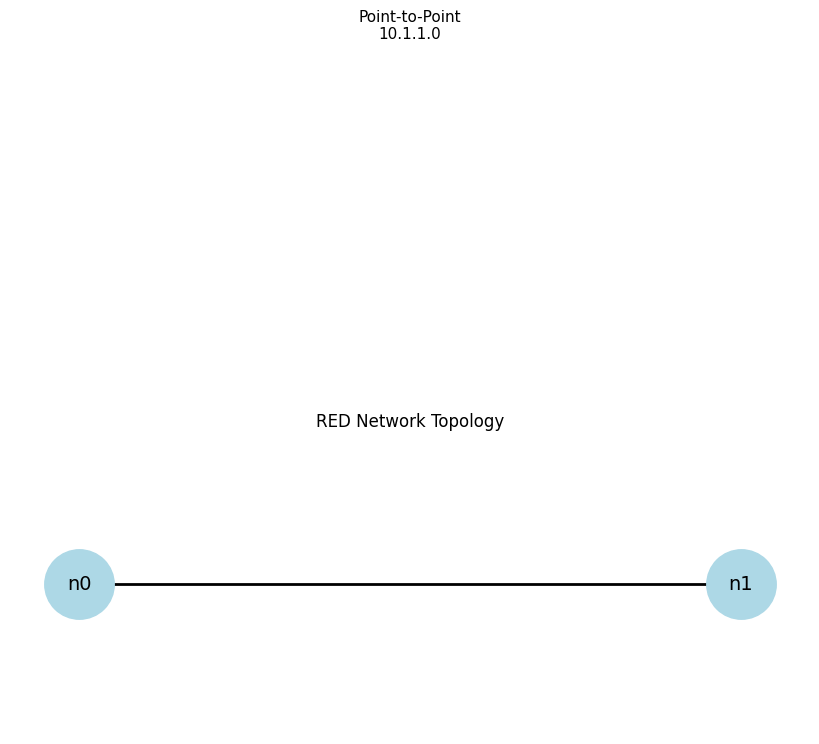

In [5]:

import matplotlib.pyplot as plt
import networkx as nx

G = nx.Graph()
G.add_edge("n0", "n1")

pos = {"n0": (0, 0), "n1": (2, 0)}

plt.figure(figsize=(8, 3))

nx.draw(
    G, pos,
    with_labels=True,
    node_color="lightblue",
    node_size=2500,
    font_size=14,
    edge_color="black",
    width=2
)

plt.text(1, 0.2, "Point-to-Point\n10.1.1.0",
         ha="center", fontsize=11)

plt.title("RED Network Topology")
plt.axis("off")
plt.show()


In [3]:
%cd /content/ns-3

!./ns3 run scratch/red-practical5

Streaming output truncated to the last 5000 lines.
RED Queue: 29 -> 28 packets
RED Queue: 28 -> 29 packets
RED: Packet dropped. Total drops = 1033
RED Queue: 29 -> 30 packets
RED: Packet dropped. Total drops = 1034
RED Queue: 30 -> 31 packets
RED Queue: 31 -> 30 packets
RED: Packet dropped. Total drops = 1035
RED Queue: 30 -> 31 packets
RED: Packet dropped. Total drops = 1036
RED Queue: 31 -> 32 packets
RED: Packet dropped. Total drops = 1037
RED Queue: 32 -> 31 packets
RED Queue: 31 -> 32 packets
RED: Packet dropped. Total drops = 1038
RED Queue: 32 -> 33 packets
RED: Packet dropped. Total drops = 1039
RED Queue: 33 -> 34 packets
RED Queue: 34 -> 33 packets
RED: Packet dropped. Total drops = 1040
RED Queue: 33 -> 34 packets
RED: Packet dropped. Total drops = 1041
RED Queue: 34 -> 35 packets
RED: Packet dropped. Total drops = 1042
RED Queue: 35 -> 36 packets
RED Queue: 36 -> 35 packets
RED: Packet dropped. Total drops = 1043
RED Queue: 35 -> 36 packets
RED: Packet dropped. Total drops 

Experiment 6

In [7]:
%%writefile /content/ns-3/scratch/wifi-practical6.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/wifi-module.h"
#include "ns3/mobility-module.h"
#include "ns3/applications-module.h"

using namespace ns3;

int main()
{
    // Create WiFi station nodes and AP
    NodeContainer wifiStaNodes;
    wifiStaNodes.Create(3);

    NodeContainer wifiApNode;
    wifiApNode.Create(1);

    // Configure WiFi channel and PHY
    YansWifiChannelHelper channel =
        YansWifiChannelHelper::Default();

    YansWifiPhyHelper phy;
    phy.SetChannel(channel.Create());

    // Configure WiFi and rate adaptation
    WifiHelper wifi;
    wifi.SetStandard(WIFI_STANDARD_80211g);

    wifi.SetRemoteStationManager(
        "ns3::MinstrelWifiManager");

    WifiMacHelper mac;
    Ssid ssid = Ssid("NS3-WiFi");

    // Configure station MAC
    mac.SetType(
        "ns3::StaWifiMac",
        "Ssid", SsidValue(ssid),
        "ActiveProbing", BooleanValue(false));

    NetDeviceContainer staDevices =
        wifi.Install(phy, mac, wifiStaNodes);

    // Configure AP MAC
    mac.SetType(
        "ns3::ApWifiMac",
        "Ssid", SsidValue(ssid));

    NetDeviceContainer apDevices =
        wifi.Install(phy, mac, wifiApNode);

    // Configure mobility
    MobilityHelper mobility;

    mobility.SetPositionAllocator(
        "ns3::GridPositionAllocator",
        "MinX", DoubleValue(0.0),
        "MinY", DoubleValue(0.0),
        "DeltaX", DoubleValue(10.0),
        "DeltaY", DoubleValue(10.0),
        "GridWidth", UintegerValue(3),
        "LayoutType", StringValue("RowFirst"));

    mobility.SetMobilityModel(
        "ns3::RandomWalk2dMobilityModel",
        "Bounds", RectangleValue(
            Rectangle(-50, 50, -50, 50)));

    mobility.Install(wifiStaNodes);

    MobilityHelper apMobility;
    apMobility.SetMobilityModel(
        "ns3::ConstantPositionMobilityModel");

    apMobility.Install(wifiApNode);

    // Install Internet stack
    InternetStackHelper stack;
    stack.Install(wifiStaNodes);
    stack.Install(wifiApNode);

    // Assign IP addresses
    Ipv4AddressHelper address;
    address.SetBase("10.1.1.0", "255.255.255.0");

    Ipv4InterfaceContainer staInterfaces =
        address.Assign(staDevices);

    Ipv4InterfaceContainer apInterface =
        address.Assign(apDevices);

    // UDP receiver at AP
    uint16_t port = 9;

    PacketSinkHelper sink(
        "ns3::UdpSocketFactory",
        InetSocketAddress(
            Ipv4Address::GetAny(), port));

    ApplicationContainer sinkApp =
        sink.Install(wifiApNode.Get(0));

    sinkApp.Start(Seconds(0.0));
    sinkApp.Stop(Seconds(10.0));

    // UDP traffic from all stations
    for (uint32_t i = 0; i < 3; i++)
    {
        OnOffHelper source(
            "ns3::UdpSocketFactory",
            InetSocketAddress(
                apInterface.GetAddress(0), port));

        source.SetAttribute(
            "DataRate", StringValue("2Mbps"));

        source.SetAttribute(
            "PacketSize", UintegerValue(1024));

        ApplicationContainer app =
            source.Install(wifiStaNodes.Get(i));

        app.Start(Seconds(1.0));
        app.Stop(Seconds(9.0));
    }

    // Run simulation
    Simulator::Stop(Seconds(10.0));
    Simulator::Run();

    // Display results
    Ptr<PacketSink> receiver =
        DynamicCast<PacketSink>(sinkApp.Get(0));

    std::cout << "\n===== WIFI RATE ADAPTATION RESULTS =====\n";

    std::cout << "WiFi Standard: IEEE 802.11g\n";
    std::cout << "Rate Adaptation: Minstrel\n";
    std::cout << "Number of Stations: 3\n";
    std::cout << "SSID: NS3-WiFi\n";

    std::cout << "Total Received Bytes: "
              << receiver->GetTotalRx() << std::endl;

    double throughput =
        receiver->GetTotalRx() * 8.0 / 10.0 / 1000000.0;

    std::cout << "Average Throughput: "
              << throughput << " Mbps\n";

    std::cout << "========================================\n";

    Simulator::Destroy();

    return 0;
}

Writing /content/ns-3/scratch/wifi-practical6.cc


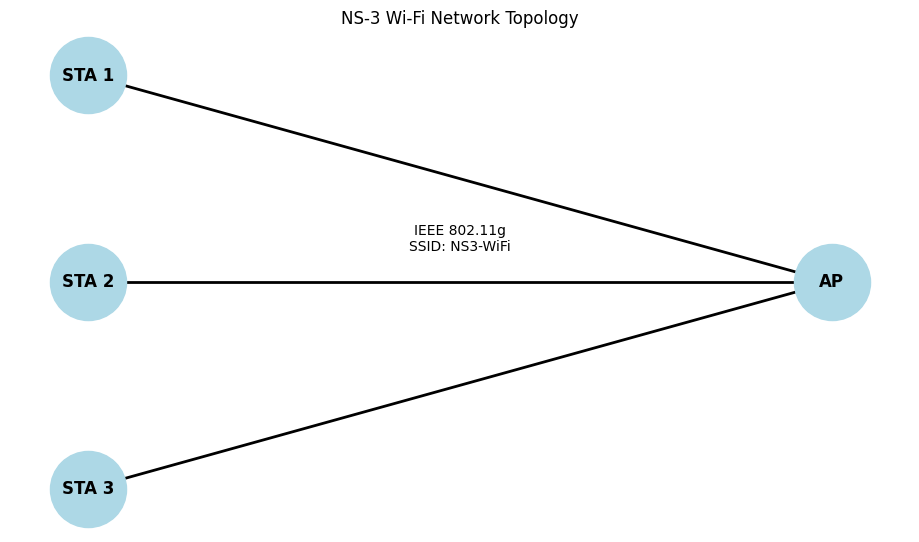

In [9]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

G.add_edges_from([
    ("STA 1", "AP"),
    ("STA 2", "AP"),
    ("STA 3", "AP")
])

pos = {
    "STA 1": (-1, 1),
    "STA 2": (-1, 0),
    "STA 3": (-1, -1),
    "AP": (1, 0)
}

plt.figure(figsize=(9, 5))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=12,
    font_weight="bold",
    edge_color="black",
    width=2
)

plt.title("NS-3 Wi-Fi Network Topology")
plt.text(0, 0.15, "IEEE 802.11g\nSSID: NS3-WiFi",
         ha="center", fontsize=10)

plt.axis("off")
plt.show()

In [8]:
%cd /content/ns-3
!./ns3 run scratch/wifi-practical6

/content/ns-3
-- Using default output directory /content/ns-3/build
-- Proceeding without cmake-format
-- find_external_library: SQLite3 was found.
CMake Warning (dev) at build-support/macros-and-definitions.cmake:839 (find_package):
  Policy CMP0167 is not set: The FindBoost module is removed.  Run "cmake
  --help-policy CMP0167" for policy details.  Use the cmake_policy command to
  set the policy and suppress this warning.

Call Stack (most recent call first):
  CMakeLists.txt:154 (process_options)
This warning is for project developers.  Use -Wno-dev to suppress it.

-- docs: doxygen documentation not enabled due to missing dependencies: doxygen dia
-- docs: sphinx documentation not enabled due to missing dependencies: epstopdf pdflatex latexmk convert dvipng dia
-- Processing src/antenna
-- Standard library Bessel function has been found
-- Processing src/aodv
-- Processing src/applications
-- Processing src/bridge
-- Processing src/brite
-- Skipping src/brite
-- Processing src/bu

Experiment 7

In [10]:

%%writefile /content/ns-3/scratch/dumbbell-practical7.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/point-to-point-module.h"
#include "ns3/applications-module.h"
#include "ns3/flow-monitor-module.h"

using namespace ns3;

int main()
{
    // Create 6 nodes
    NodeContainer clients, routers, servers;
    clients.Create(2);
    routers.Create(2);
    servers.Create(2);

    // Access links
    PointToPointHelper access;
    access.SetDeviceAttribute("DataRate", StringValue("100Mbps"));
    access.SetChannelAttribute("Delay", StringValue("2ms"));

    // Bottleneck link
    PointToPointHelper bottleneck;
    bottleneck.SetDeviceAttribute("DataRate", StringValue("10Mbps"));
    bottleneck.SetChannelAttribute("Delay", StringValue("10ms"));

    // Connect clients to left router
    NetDeviceContainer c1 = access.Install(clients.Get(0), routers.Get(0));
    NetDeviceContainer c2 = access.Install(clients.Get(1), routers.Get(0));

    // Connect the two routers
    NetDeviceContainer bridge = bottleneck.Install(routers);

    // Connect right router to servers
    NetDeviceContainer s1 = access.Install(routers.Get(1), servers.Get(0));
    NetDeviceContainer s2 = access.Install(routers.Get(1), servers.Get(1));

    // Install Internet stack
    InternetStackHelper internet;
    internet.Install(clients);
    internet.Install(routers);
    internet.Install(servers);

    // Assign IP addresses
    Ipv4AddressHelper ip;

    ip.SetBase("10.1.1.0", "255.255.255.0");
    ip.Assign(c1);

    ip.SetBase("10.1.2.0", "255.255.255.0");
    ip.Assign(c2);

    ip.SetBase("10.1.3.0", "255.255.255.0");
    ip.Assign(bridge);

    ip.SetBase("10.1.4.0", "255.255.255.0");
    Ipv4InterfaceContainer server1 = ip.Assign(s1);

    ip.SetBase("10.1.5.0", "255.255.255.0");
    Ipv4InterfaceContainer server2 = ip.Assign(s2);

    // Enable routing
    Ipv4GlobalRoutingHelper::PopulateRoutingTables();

    // TCP receiver on Server 1
    uint16_t tcpPort = 50000;

    PacketSinkHelper tcpSink(
        "ns3::TcpSocketFactory",
        InetSocketAddress(Ipv4Address::GetAny(), tcpPort));

    ApplicationContainer tcpReceiver =
        tcpSink.Install(servers.Get(0));

    tcpReceiver.Start(Seconds(0));
    tcpReceiver.Stop(Seconds(40));

    // TCP sender: Client 1 -> Server 1
    BulkSendHelper tcpSource(
        "ns3::TcpSocketFactory",
        InetSocketAddress(server1.GetAddress(1), tcpPort));

    tcpSource.SetAttribute("MaxBytes", UintegerValue(0));
    tcpSource.SetAttribute("SendSize", UintegerValue(1024));

    ApplicationContainer tcpSender =
        tcpSource.Install(clients.Get(0));

    tcpSender.Start(Seconds(1));
    tcpSender.Stop(Seconds(40));

    // UDP receiver on Server 2
    uint16_t udpPort = 50001;

    PacketSinkHelper udpSink(
        "ns3::UdpSocketFactory",
        InetSocketAddress(Ipv4Address::GetAny(), udpPort));

    ApplicationContainer udpReceiver =
        udpSink.Install(servers.Get(1));

    udpReceiver.Start(Seconds(0));
    udpReceiver.Stop(Seconds(40));

    // UDP Rate 1: Half bottleneck capacity (5 Mbps)
    OnOffHelper udpSource1(
        "ns3::UdpSocketFactory",
        InetSocketAddress(server2.GetAddress(1), udpPort));

    udpSource1.SetAttribute("DataRate", StringValue("5Mbps"));
    udpSource1.SetAttribute("PacketSize", UintegerValue(1024));
    udpSource1.SetAttribute("OnTime",
        StringValue("ns3::ConstantRandomVariable[Constant=1]"));
    udpSource1.SetAttribute("OffTime",
        StringValue("ns3::ConstantRandomVariable[Constant=0]"));

    ApplicationContainer udpApp1 =
        udpSource1.Install(clients.Get(1));

    udpApp1.Start(Seconds(20));
    udpApp1.Stop(Seconds(30));

    // UDP Rate 2: Full bottleneck capacity (10 Mbps)
    OnOffHelper udpSource2(
        "ns3::UdpSocketFactory",
        InetSocketAddress(server2.GetAddress(1), udpPort));

    udpSource2.SetAttribute("DataRate", StringValue("10Mbps"));
    udpSource2.SetAttribute("PacketSize", UintegerValue(1024));
    udpSource2.SetAttribute("OnTime",
        StringValue("ns3::ConstantRandomVariable[Constant=1]"));
    udpSource2.SetAttribute("OffTime",
        StringValue("ns3::ConstantRandomVariable[Constant=0]"));

    ApplicationContainer udpApp2 =
        udpSource2.Install(clients.Get(1));

    udpApp2.Start(Seconds(30));
    udpApp2.Stop(Seconds(40));

    // Flow monitor
    FlowMonitorHelper flowHelper;
    Ptr<FlowMonitor> monitor = flowHelper.InstallAll();

    // Run simulation
    Simulator::Stop(Seconds(40));
    Simulator::Run();

    monitor->CheckForLostPackets();

    std::cout << "\n===== DUMBBELL NETWORK RESULTS =====\n";

    Ptr<PacketSink> tcpRx =
        DynamicCast<PacketSink>(tcpReceiver.Get(0));

    Ptr<PacketSink> udpRx =
        DynamicCast<PacketSink>(udpReceiver.Get(0));

    std::cout << "\nTCP Received Bytes: "
              << tcpRx->GetTotalRx();

    std::cout << "\nUDP Received Bytes: "
              << udpRx->GetTotalRx();

    std::cout << "\nTCP Average Throughput: "
              << tcpRx->GetTotalRx() * 8.0 / 39.0 / 1e6
              << " Mbps";

    std::cout << "\nUDP Average Throughput: "
              << udpRx->GetTotalRx() * 8.0 / 20.0 / 1e6
              << " Mbps";

    std::cout << "\n====================================\n";

    monitor->SerializeToXmlFile(
        "/content/dumbbell-flowmon.xml", true, true);

    Simulator::Destroy();

    return 0;
}


Writing /content/ns-3/scratch/dumbbell-practical7.cc


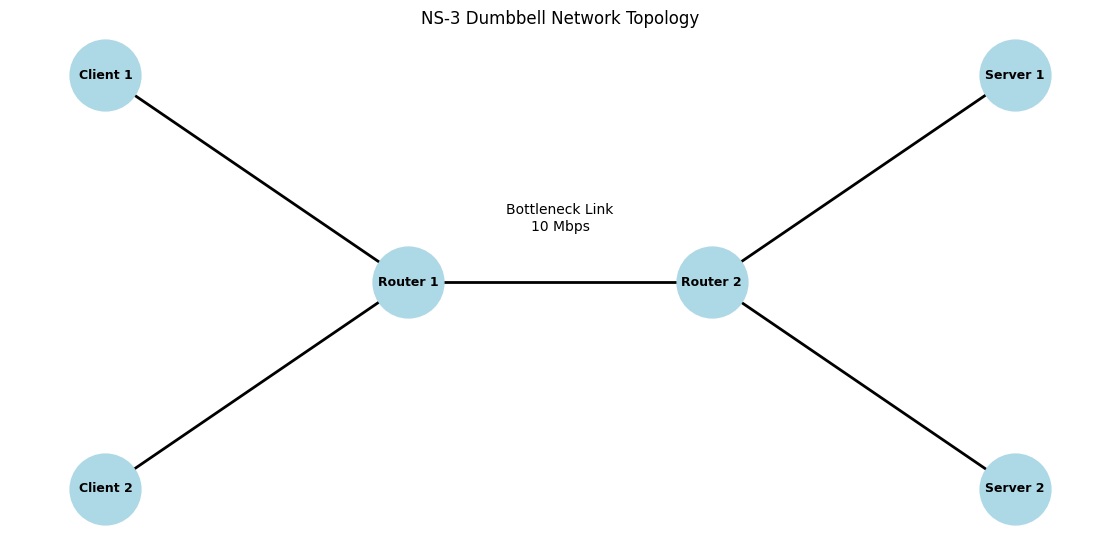

In [11]:

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

edges = [
    ("Client 1", "Router 1"),
    ("Client 2", "Router 1"),
    ("Router 1", "Router 2"),
    ("Router 2", "Server 1"),
    ("Router 2", "Server 2")
]

G.add_edges_from(edges)

pos = {
    "Client 1": (0, 1),
    "Client 2": (0, -1),
    "Router 1": (2, 0),
    "Router 2": (4, 0),
    "Server 1": (6, 1),
    "Server 2": (6, -1)
}

plt.figure(figsize=(11, 5))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=2600,
    node_color="lightblue",
    font_size=9,
    font_weight="bold",
    width=2
)

plt.text(3, 0.25, "Bottleneck Link\n10 Mbps",
         ha="center", fontsize=10)

plt.title("NS-3 Dumbbell Network Topology")
plt.axis("off")
plt.show()


In [12]:
%cd /content/ns-3
!./ns3 run scratch/dumbbell-practical7

/content/ns-3
-- Using default output directory /content/ns-3/build
-- Proceeding without cmake-format
-- find_external_library: SQLite3 was found.
CMake Warning (dev) at build-support/macros-and-definitions.cmake:839 (find_package):
  Policy CMP0167 is not set: The FindBoost module is removed.  Run "cmake
  --help-policy CMP0167" for policy details.  Use the cmake_policy command to
  set the policy and suppress this warning.

Call Stack (most recent call first):
  CMakeLists.txt:154 (process_options)
This warning is for project developers.  Use -Wno-dev to suppress it.

-- docs: doxygen documentation not enabled due to missing dependencies: doxygen dia
-- docs: sphinx documentation not enabled due to missing dependencies: epstopdf pdflatex latexmk convert dvipng dia
-- Processing src/antenna
-- Standard library Bessel function has been found
-- Processing src/aodv
-- Processing src/applications
-- Processing src/bridge
-- Processing src/brite
-- Skipping src/brite
-- Processing src/bu

Experiment 08

In [13]:

%%writefile /content/ns-3/scratch/adhoc-practical8.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/wifi-module.h"
#include "ns3/mobility-module.h"
#include "ns3/applications-module.h"

using namespace ns3;

NS_LOG_COMPONENT_DEFINE("AdhocScriptExample");

int main()
{
    LogComponentEnable("UdpEchoClientApplication", LOG_LEVEL_INFO);
    LogComponentEnable("UdpEchoServerApplication", LOG_LEVEL_INFO);

    // Create two nodes
    NodeContainer nodes;
    nodes.Create(2);

    // Configure WiFi channel
    YansWifiChannelHelper channel =
        YansWifiChannelHelper::Default();

    YansWifiPhyHelper phy;
    phy.SetChannel(channel.Create());

    // Configure 802.11b WiFi
    WifiHelper wifi;
    wifi.SetStandard(WIFI_STANDARD_80211b);

    wifi.SetRemoteStationManager(
        "ns3::ConstantRateWifiManager",
        "DataMode", StringValue("DsssRate2Mbps"),
        "ControlMode", StringValue("DsssRate1Mbps"));

    // Ad hoc MAC configuration
    WifiMacHelper mac;
    mac.SetType("ns3::AdhocWifiMac");

    NetDeviceContainer devices =
        wifi.Install(phy, mac, nodes);

    // Node positions
    MobilityHelper mobility;

    Ptr<ListPositionAllocator> position =
        CreateObject<ListPositionAllocator>();

    position->Add(Vector(0, 0, 0));
    position->Add(Vector(10, 0, 0));

    mobility.SetPositionAllocator(position);

    mobility.SetMobilityModel(
        "ns3::ConstantPositionMobilityModel");

    mobility.Install(nodes);

    // Internet stack
    InternetStackHelper internet;
    internet.Install(nodes);

    // Assign IP addresses
    Ipv4AddressHelper address;
    address.SetBase("10.1.1.0", "255.255.255.0");

    Ipv4InterfaceContainer interfaces =
        address.Assign(devices);

    // UDP Echo Server
    uint16_t port = 9;

    UdpEchoServerHelper server(port);

    ApplicationContainer serverApp =
        server.Install(nodes.Get(1));

    serverApp.Start(Seconds(1.0));
    serverApp.Stop(Seconds(10.0));

    // UDP Echo Client
    UdpEchoClientHelper client(
        interfaces.GetAddress(1), port);

    client.SetAttribute("MaxPackets", UintegerValue(5));
    client.SetAttribute("Interval", TimeValue(Seconds(1.0)));
    client.SetAttribute("PacketSize", UintegerValue(1024));

    ApplicationContainer clientApp =
        client.Install(nodes.Get(0));

    clientApp.Start(Seconds(2.0));
    clientApp.Stop(Seconds(10.0));

    // Run simulation
    Simulator::Stop(Seconds(10.0));
    Simulator::Run();

    std::cout << "\n===== AD HOC NETWORK RESULTS =====\n";
    std::cout << "WiFi Standard: 802.11b\n";
    std::cout << "Network IP: 10.1.1.0\n";
    std::cout << "Client IP: " << interfaces.GetAddress(0) << "\n";
    std::cout << "Server IP: " << interfaces.GetAddress(1) << "\n";
    std::cout << "Packet Size: 1024 bytes\n";
    std::cout << "Packets Sent: 5\n";
    std::cout << "==================================\n";

    Simulator::Destroy();

    return 0;
}


Writing /content/ns-3/scratch/adhoc-practical8.cc


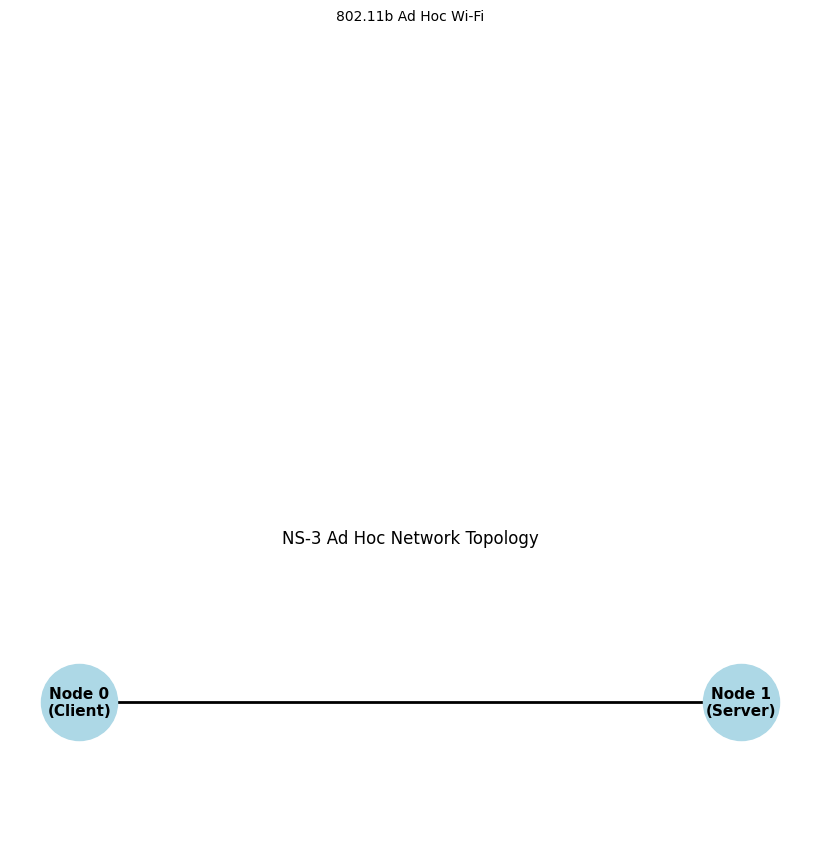

In [14]:

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_edge("Node 0\n(Client)", "Node 1\n(Server)")

pos = {
    "Node 0\n(Client)": (0, 0),
    "Node 1\n(Server)": (3, 0)
}

plt.figure(figsize=(8, 3))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=11,
    font_weight="bold",
    edge_color="black",
    width=2
)

plt.text(1.5, 0.25, "802.11b Ad Hoc Wi-Fi", ha="center")
plt.title("NS-3 Ad Hoc Network Topology")
plt.axis("off")
plt.show()


In [15]:
%cd /content/ns-3
!./ns3 run scratch/adhoc-practical8

/content/ns-3
-- Using default output directory /content/ns-3/build
-- Proceeding without cmake-format
-- find_external_library: SQLite3 was found.
CMake Warning (dev) at build-support/macros-and-definitions.cmake:839 (find_package):
  Policy CMP0167 is not set: The FindBoost module is removed.  Run "cmake
  --help-policy CMP0167" for policy details.  Use the cmake_policy command to
  set the policy and suppress this warning.

Call Stack (most recent call first):
  CMakeLists.txt:154 (process_options)
This warning is for project developers.  Use -Wno-dev to suppress it.

-- docs: doxygen documentation not enabled due to missing dependencies: doxygen dia
-- docs: sphinx documentation not enabled due to missing dependencies: epstopdf pdflatex latexmk convert dvipng dia
-- Processing src/antenna
-- Standard library Bessel function has been found
-- Processing src/aodv
-- Processing src/applications
-- Processing src/bridge
-- Processing src/brite
-- Skipping src/brite
-- Processing src/bu

CBS 01

In [16]:

%%writefile /content/ns-3/scratch/udp-practical9.cc

#include "ns3/core-module.h"
#include "ns3/network-module.h"
#include "ns3/internet-module.h"
#include "ns3/point-to-point-module.h"
#include "ns3/applications-module.h"

using namespace ns3;

int main()
{
    // Create two nodes
    NodeContainer nodes;
    nodes.Create(2);

    // Point-to-point link
    PointToPointHelper p2p;

    p2p.SetDeviceAttribute(
        "DataRate", StringValue("5Mbps"));

    p2p.SetChannelAttribute(
        "Delay", StringValue("2ms"));

    NetDeviceContainer devices = p2p.Install(nodes);

    // Install Internet stack
    InternetStackHelper stack;
    stack.Install(nodes);

    // Assign IP addresses
    Ipv4AddressHelper address;
    address.SetBase("10.1.1.0", "255.255.255.0");

    Ipv4InterfaceContainer interfaces =
        address.Assign(devices);

    uint16_t port = 9;

    // UDP Server on Node 2
    UdpServerHelper server(port);

    ApplicationContainer serverApp =
        server.Install(nodes.Get(1));

    serverApp.Start(Seconds(1.0));
    serverApp.Stop(Seconds(10.0));

    // UDP Client on Node 1
    UdpClientHelper client(
        interfaces.GetAddress(1), port);

    client.SetAttribute(
        "MaxPackets", UintegerValue(10));

    client.SetAttribute(
        "Interval", TimeValue(Seconds(1.0)));

    client.SetAttribute(
        "PacketSize", UintegerValue(1024));

    ApplicationContainer clientApp =
        client.Install(nodes.Get(0));

    clientApp.Start(Seconds(2.0));
    clientApp.Stop(Seconds(10.0));

    // Run simulation
    Simulator::Stop(Seconds(10.0));
    Simulator::Run();

    // Display results
    Ptr<UdpServer> udpServer =
        DynamicCast<UdpServer>(serverApp.Get(0));

    std::cout << "\n===== UDP TRANSFER RESULTS =====\n";
    std::cout << "Client IP: " << interfaces.GetAddress(0) << "\n";
    std::cout << "Server IP: " << interfaces.GetAddress(1) << "\n";
    std::cout << "Packets Sent: 10\n";
    std::cout << "Packets Received: "
              << udpServer->GetReceived() << "\n";
    std::cout << "Packet Size: 1024 bytes\n";
    std::cout << "================================\n";

    Simulator::Destroy();

    return 0;
}


Writing /content/ns-3/scratch/udp-practical9.cc


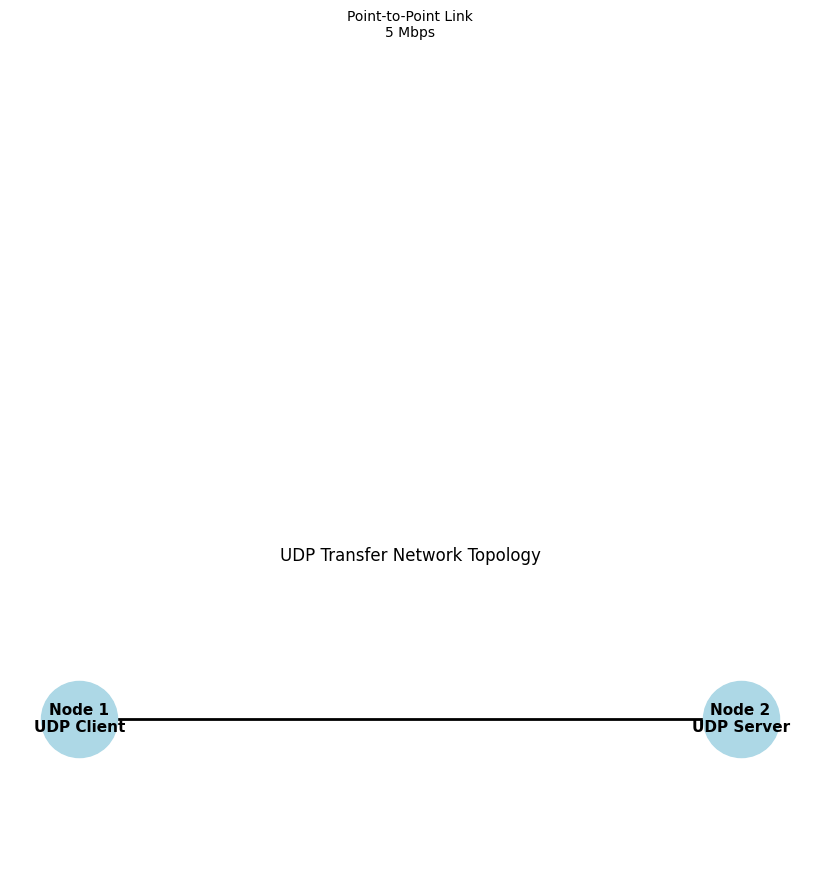

In [17]:

import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()
G.add_edge("Node 1\nUDP Client", "Node 2\nUDP Server")

pos = {
    "Node 1\nUDP Client": (0, 0),
    "Node 2\nUDP Server": (3, 0)
}

plt.figure(figsize=(8, 3))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=3000,
    node_color="lightblue",
    font_size=11,
    font_weight="bold",
    edge_color="black",
    width=2
)

plt.text(1.5, 0.25, "Point-to-Point Link\n5 Mbps",
         ha="center")

plt.title("UDP Transfer Network Topology")
plt.axis("off")
plt.show()


In [18]:
%cd /content/ns-3
!./ns3 run scratch/udp-practical9

/content/ns-3
-- Using default output directory /content/ns-3/build
-- Proceeding without cmake-format
-- find_external_library: SQLite3 was found.
CMake Warning (dev) at build-support/macros-and-definitions.cmake:839 (find_package):
  Policy CMP0167 is not set: The FindBoost module is removed.  Run "cmake
  --help-policy CMP0167" for policy details.  Use the cmake_policy command to
  set the policy and suppress this warning.

Call Stack (most recent call first):
  CMakeLists.txt:154 (process_options)
This warning is for project developers.  Use -Wno-dev to suppress it.

-- docs: doxygen documentation not enabled due to missing dependencies: doxygen dia
-- docs: sphinx documentation not enabled due to missing dependencies: epstopdf pdflatex latexmk convert dvipng dia
-- Processing src/antenna
-- Standard library Bessel function has been found
-- Processing src/aodv
-- Processing src/applications
-- Processing src/bridge
-- Processing src/brite
-- Skipping src/brite
-- Processing src/bu

In [30]:

import os
import glob
import subprocess
import zipfile
from datetime import datetime

BASE = "/content/ns-3"
OUTPUT = "/content/NS3_Practicals_2_to_9.zip"
RESULTS = "/content/Practical_Results"

os.makedirs(RESULTS, exist_ok=True)

# Practical number : simulation filename
practicals = {
    3: "udp-echo-practical3",
    4: "csma-p2p-practical4",
    5: "red-practical5",
    6: "wifi-practical6",
    7: "dumbbell-practical7",
    8: "adhoc-practical8",
    9: "udp-practical9"
}

readme = [
    "NS-3 NETWORK SIMULATION PRACTICALS (2-9)",
    "=" * 55,
    f"Generated: {datetime.now()}",
    "",
    "FILE DIRECTORY AND PRACTICAL MAPPING",
    "-" * 55,
    "Practical 2: NS-3 Installation and Configuration",
    "  - Practical_2_Setup.txt",
    "",
]

# Practical 2 setup record
setup = subprocess.run(
    ["./ns3", "--version"],
    cwd=BASE,
    capture_output=True,
    text=True
)

with open(os.path.join(RESULTS, "Practical_2_Setup.txt"), "w") as f:
    f.write("PRACTICAL 2: NS-3 INSTALLATION\n\n")
    f.write("NS-3 Version:\n")
    f.write(setup.stdout)
    f.write(setup.stderr)

# Execute each practical and save output
for number, name in practicals.items():

    source = os.path.join(BASE, "scratch", name + ".cc")
    log = os.path.join(RESULTS, f"Practical_{number}_Output.txt")

    readme.append(
        f"Practical {number}: {name}\n"
        f"  - scratch/{name}.cc\n"
        f"  - Practical_{number}_Output.txt\n"
    )

    if not os.path.exists(source):
        with open(log, "w") as f:
            f.write("Source file not found: " + source)
        continue

    print(f"Running Practical {number}...")

    result = subprocess.run(
        ["./ns3", "run", f"scratch/{name}"],
        cwd=BASE,
        capture_output=True,
        text=True
    )

    with open(log, "w") as f:
        f.write(f"PRACTICAL {number} OUTPUT\n")
        f.write("=" * 45 + "\n\n")
        f.write("COMMAND: ./ns3 run scratch/" + name + "\n\n")
        f.write("RETURN CODE: " + str(result.returncode) + "\n\n")
        f.write("STANDARD OUTPUT:\n")
        f.write(result.stdout)
        f.write("\nSTANDARD ERROR:\n")
        f.write(result.stderr)

    print("Completed:", number, "| Exit code:", result.returncode)

readme.extend([
    "",
    "OUTPUT FILES",
    "-" * 55,
    "Practical output logs are stored in Practical_Results/.",
    "PCAP files contain packet captures for Wireshark.",
    "CSV files contain recorded simulation data, if generated.",
    "XML files contain FlowMonitor results, if generated.",
    "PNG files contain saved diagrams, if generated.",
    "",
    "IMPORTANT:",
    "Only files actually generated or present are included.",
    "A failed simulation is identified by its non-zero exit code.",
    "Check individual output logs for errors.",
    "",
])

# Collect files into ZIP
with zipfile.ZipFile(OUTPUT, "w", zipfile.ZIP_DEFLATED) as z:

    z.write(
        os.path.join(RESULTS, "Practical_2_Setup.txt"),
        "Practical_Results/Practical_2_Setup.txt"
    )

    for file in glob.glob(RESULTS + "/*.txt"):
        if os.path.basename(file) != "Practical_2_Setup.txt":
            z.write(file, "Practical_Results/" + os.path.basename(file))

    # Collect source codes
    for file in glob.glob(BASE + "/scratch/*.cc"):
        z.write(file, "Source_Codes/" + os.path.basename(file))

    # Collect generated output files, excluding build directory
    for ext in ["*.pcap", "*.pcapng", "*.csv", "*.xml", "*.png"]:
        for folder in [BASE, BASE + "/scratch"]:
            for file in glob.glob(folder + "/" + ext):
                z.write(file, "Generated_Outputs/" + os.path.basename(file))

    # README
    z.writestr("README.txt", "\n".join(readme))

print("\nZIP CREATED:", OUTPUT)
print("Download size:", round(os.path.getsize(OUTPUT) / 1024, 2), "KB")

from google.colab import files
files.download(OUTPUT)


Running Practical 3...
Completed: 3 | Exit code: 0
Running Practical 4...
Completed: 4 | Exit code: 0
Running Practical 5...
Completed: 5 | Exit code: 0
Running Practical 6...
Completed: 6 | Exit code: 0
Running Practical 7...
Completed: 7 | Exit code: 0
Running Practical 8...
Completed: 8 | Exit code: 0
Running Practical 9...
Completed: 9 | Exit code: 0

ZIP CREATED: /content/NS3_Practicals_2_to_9.zip
Download size: 32.45 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mini Project

Extended Project